Name : Nikeeta Sandeep Gurve

Roll Number: 9

Section : B1

Batch : B1

SI Lab 8

Part 1 — Load and inspect the dataset

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

uploaded = files.upload()

df = pd.read_csv("insurance.csv")

print("First 5 rows:")
display(df.head())

print("Last 5 rows:")
display(df.tail())

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print("Data types:")
print(df.dtypes)

print("Dataset information:")
df.info()

print("Missing values:")
print(df.isnull().sum())

print("Duplicate records:", df.duplicated().sum())

Saving insurance.csv to insurance.csv
First 5 rows:


,age,sex,bmi,children,smoker,region,charges
0,19.0,female,27.900,0,yes,southwest,16884.92400
1,18.0,male,33.770,1,no,southeast,1725.55230
2,28.0,male,33.000,3,no,southeast,4449.46200
3,33.0,male,22.705,0,no,northwest,21984.47061
4,32.0,male,28.880,0,no,northwest,3866.85520


Last 5 rows:


,age,sex,bmi,children,smoker,region,charges
1333,50.0,male,30.97,3,no,northwest,10600.5483
1334,18.0,female,31.92,0,no,northeast,2205.9808
1335,18.0,female,36.85,0,no,southeast,1629.8335
1336,21.0,female,25.80,0,no,southwest,2007.9450
1337,61.0,female,29.07,0,yes,northwest,29141.3603


Shape: (1338, 7)
Columns: ['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']
Data types:
age         float64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object
Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1334 non-null   float64
 1   sex       1338 non-null   object 
 2   bmi       1336 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(3), int64(1), object(3)
memory usage: 73.3+ KB
Missing values:
age         4
sex         0
bmi         2
children    0
smoker      0
region      0
charges     0
dtype: int64
Duplicate records: 1


Part 2 — Exploratory Data Analysis (EDA)

In [3]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()
cat_cols = df.select_dtypes(include="object").columns.tolist()

print("Numerical variables:", num_cols)
print("Categorical variables:", cat_cols)

Numerical variables: ['age', 'bmi', 'children', 'charges']
Categorical variables: ['sex', 'smoker', 'region']


Distribution plots

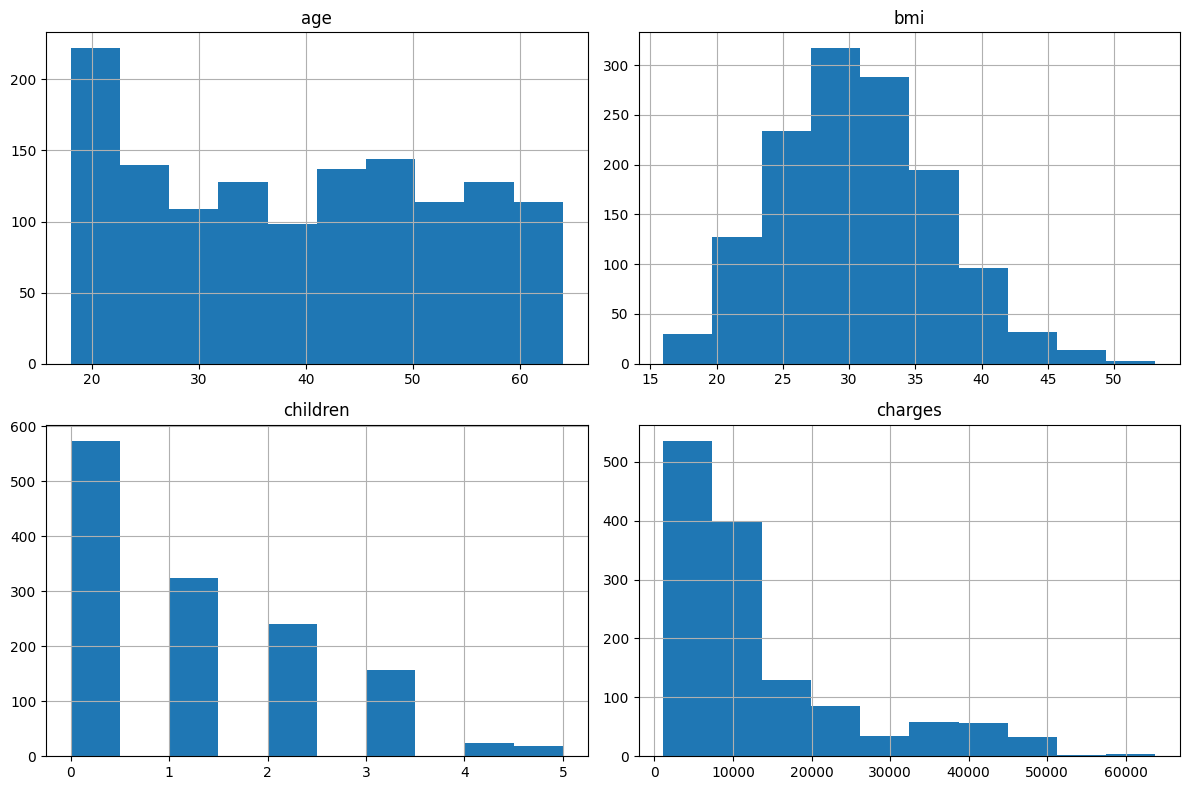

In [4]:
df[num_cols].hist(figsize=(12, 8))
plt.tight_layout()
plt.show()

Box plots

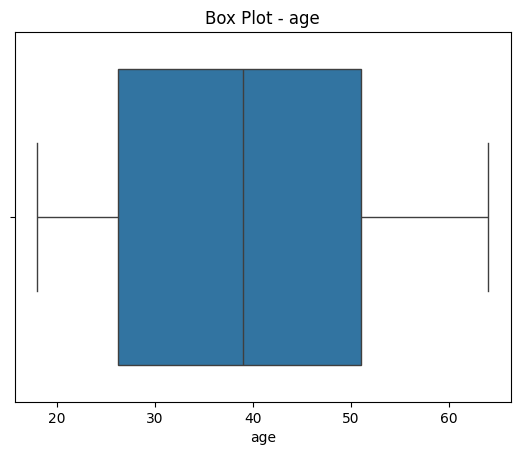

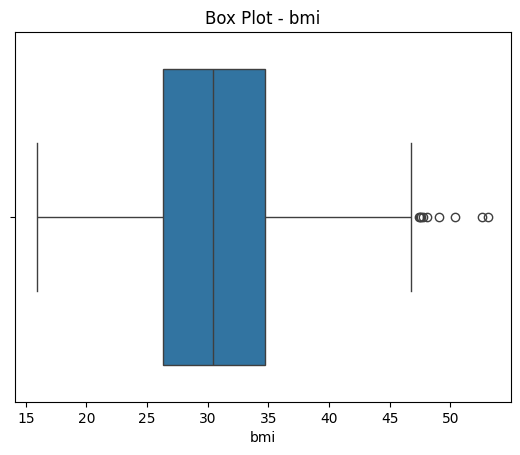

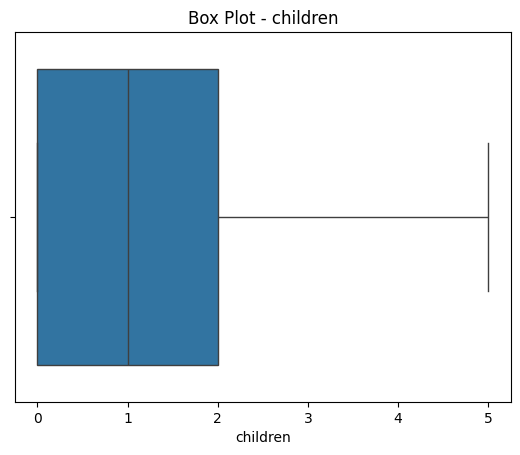

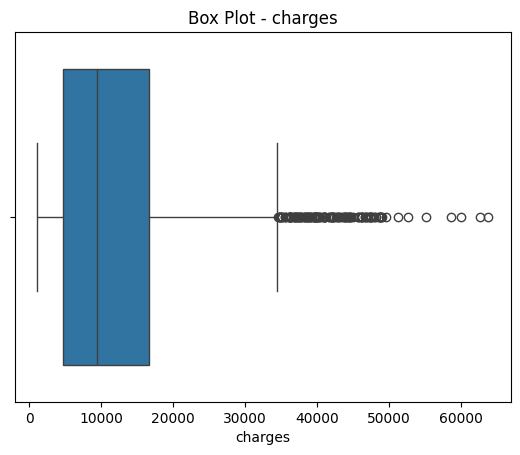

In [5]:
for col in num_cols:
    sns.boxplot(x=df[col])
    plt.title("Box Plot - " + col)
    plt.show()

Scatter plots

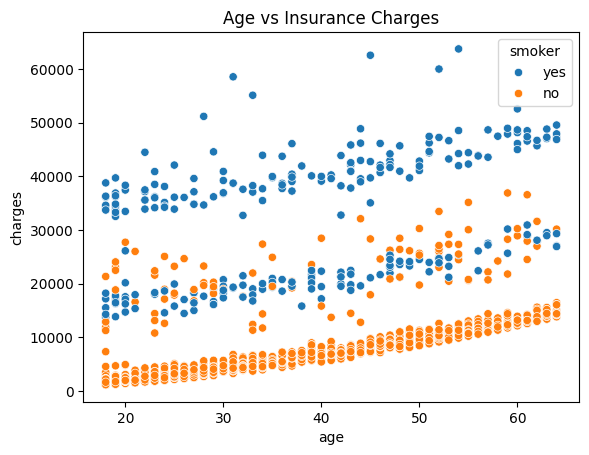

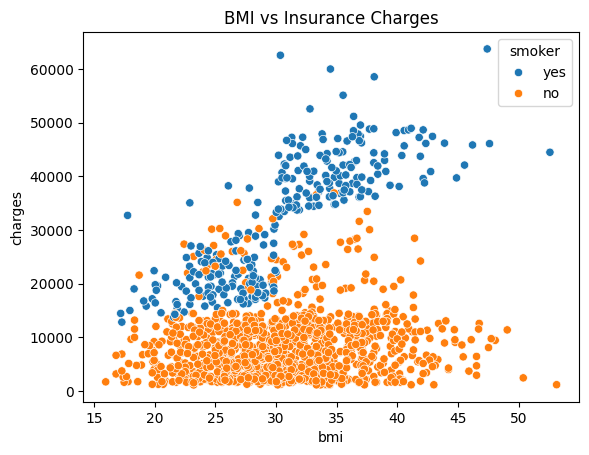

In [6]:
sns.scatterplot(data=df, x="age", y="charges", hue="smoker")
plt.title("Age vs Insurance Charges")
plt.show()

sns.scatterplot(data=df, x="bmi", y="charges", hue="smoker")
plt.title("BMI vs Insurance Charges")
plt.show()

Categorical variable visualization

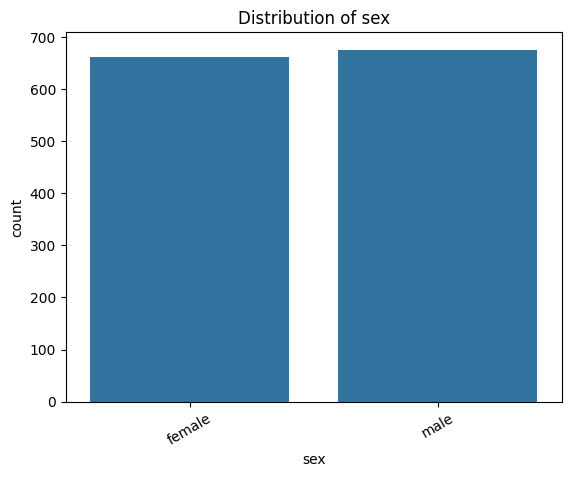

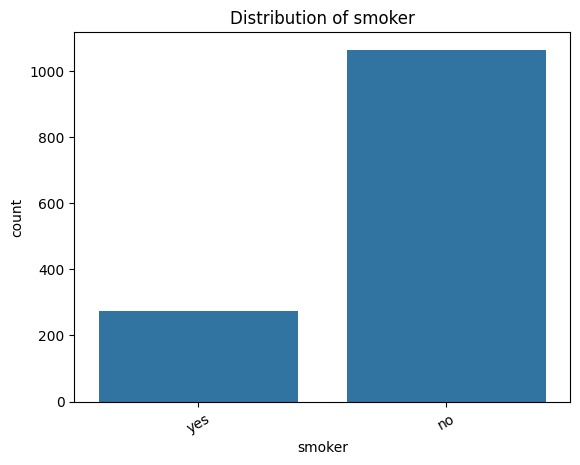

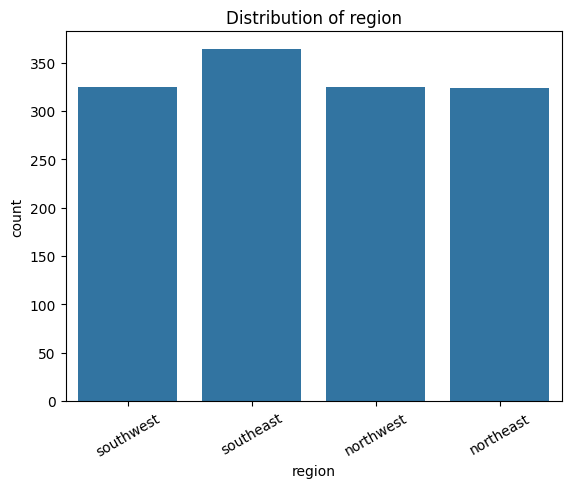

In [7]:
for col in cat_cols:
    sns.countplot(data=df, x=col)
    plt.title("Distribution of " + col)
    plt.xticks(rotation=30)
    plt.show()

Part 3 — Data preprocessing

In [8]:
df = df.drop_duplicates().copy()

X = df.drop("charges", axis=1)
y = df["charges"]

num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(include="object").columns.tolist()

print("Numerical columns:", num_cols)
print("Categorical columns:", cat_cols)

Numerical columns: ['age', 'bmi', 'children']
Categorical columns: ['sex', 'smoker', 'region']


Part 4 — Correlation and covariance analysis

Correlation Matrix:


,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
age,1.000000,0.109520,0.041537,0.298485,-0.019949,-0.025567,0.001463,-0.012266,0.009366
bmi,0.109520,1.000000,0.012901,0.198439,0.046443,0.003708,-0.136283,0.270086,-0.006159
children,0.041537,0.012901,1.000000,0.067389,0.017848,0.007331,0.026044,-0.023492,0.021538
charges,0.298485,0.198439,0.067389,1.000000,0.058044,0.787234,-0.038695,0.073578,-0.043637
sex_male,-0.019949,0.046443,0.017848,0.058044,1.000000,0.076596,-0.012482,0.017578,-0.003767
smoker_yes,-0.025567,0.003708,0.007331,0.787234,0.076596,1.000000,-0.036321,0.068282,-0.037168
region_northwest,0.001463,-0.136283,0.026044,-0.038695,-0.012482,-0.036321,1.000000,-0.345909,-0.320493
region_southeast,-0.012266,0.270086,-0.023492,0.073578,0.017578,0.068282,-0.345909,1.000000,-0.346614
region_southwest,0.009366,-0.006159,0.021538,-0.043637,-0.003767,-0.037168,-0.320493,-0.346614,1.000000


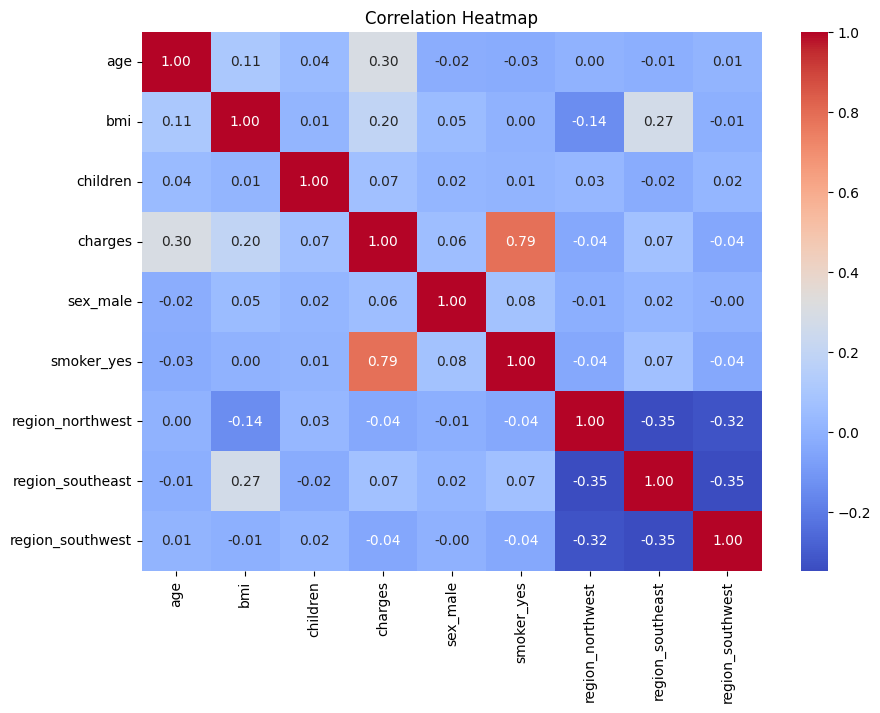

Covariance Matrix:


,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
age,197.834621,9.408145,0.704876,5.089485e+04,-0.140344,-0.145374,0.008814,-0.076827,0.056529
bmi,9.408145,37.271359,0.094842,1.467824e+04,0.141816,0.009146,-0.356452,0.734567,-0.016125
children,0.704876,0.094842,1.453402,9.838780e+02,0.010762,0.003569,0.013459,-0.012611,0.011142
charges,50894.852365,14678.236929,983.878025,1.466608e+08,351.584753,3849.763649,-200.870455,396.773609,-226.766344
sex_male,-0.140344,0.141816,0.010762,3.515848e+02,0.250163,0.015470,-0.002676,0.003915,-0.000808
smoker_yes,-0.145374,0.009146,0.003569,3.849764e+03,0.015470,0.163059,-0.006287,0.012278,-0.006440
region_northwest,0.008814,-0.356452,0.013459,-2.008705e+02,-0.002676,-0.006287,0.183745,-0.066025,-0.058951
region_southeast,-0.076827,0.734567,-0.012611,3.967736e+02,0.003915,0.012278,-0.066025,0.198279,-0.066229
region_southwest,0.056529,-0.016125,0.011142,-2.267663e+02,-0.000808,-0.006440,-0.058951,-0.066229,0.184131


In [9]:
encoded_df = pd.get_dummies(df, drop_first=True, dtype=int)

print("Correlation Matrix:")
display(encoded_df.corr(numeric_only=True))

plt.figure(figsize=(10, 7))
sns.heatmap(encoded_df.corr(numeric_only=True), annot=True,
            cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

print("Covariance Matrix:")
display(encoded_df.cov(numeric_only=True))

Part 5 — Train-test split and model training

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, num_cols),
    ("cat", categorical_pipeline, cat_cols)
])

models = {
    "Multiple Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=0.1, max_iter=10000),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(
        n_estimators=100, random_state=42
    )
}

trained_models = {}
results = []

for name, regressor in models.items():
    model = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", regressor)
    ])

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    trained_models[name] = model

    mse = mean_squared_error(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2 Score": r2_score(y_test, predictions)
    })

comparison = pd.DataFrame(results).sort_values(
    by="R2 Score", ascending=False
)

display(comparison)

,Model,MAE,MSE,RMSE,R2 Score
4,Random Forest,2585.360943,2.188500e+07,4678.140945,0.880902
0,Multiple Linear Regression,4177.183663,3.547914e+07,5956.436613,0.806923
2,Lasso Regression,4177.262990,3.548052e+07,5956.552283,0.806915
1,Ridge Regression,4185.544589,3.557372e+07,5964.370943,0.806408
3,Decision Tree,2898.381618,3.965701e+07,6297.381097,0.784187


Part 6 — Select and save the best model

In [11]:
best_name = comparison.iloc[0]["Model"]
best_model = trained_models[best_name]

print("Best Model:", best_name)
print("Best R2 Score:", comparison.iloc[0]["R2 Score"])

import joblib

joblib.dump(best_model, "best_insurance_model.pkl")
print("Best model saved successfully.")

Best Model: Random Forest
Best R2 Score: 0.8809018748954627
Best model saved successfully.


Part 7 — Visualize model comparison

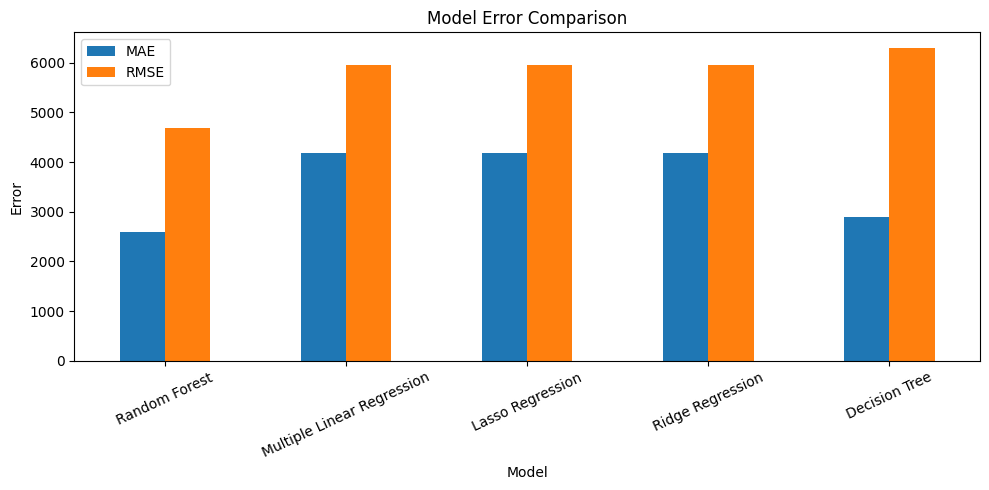

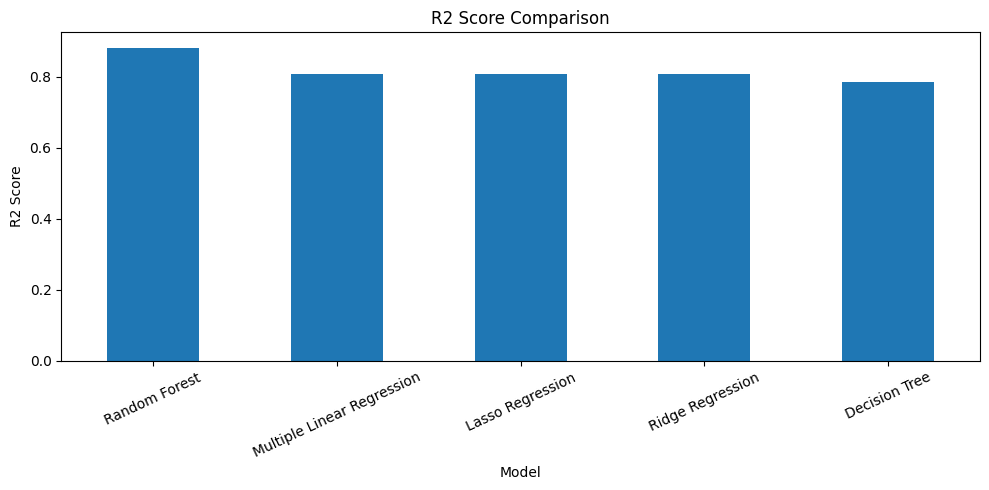

In [12]:
comparison.set_index("Model")[["MAE", "RMSE"]].plot(
    kind="bar", figsize=(10, 5)
)
plt.title("Model Error Comparison")
plt.ylabel("Error")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

comparison.set_index("Model")["R2 Score"].plot(
    kind="bar", figsize=(10, 5)
)
plt.title("R2 Score Comparison")
plt.ylabel("R2 Score")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

Part 8 — Create a prediction interface

In [13]:
import joblib

best_model = joblib.load("best_insurance_model.pkl")

age = int(input("Enter age: "))
sex = input("Enter sex (male/female): ").lower()
bmi = float(input("Enter BMI: "))
children = int(input("Enter number of children: "))
smoker = input("Is the person a smoker? (yes/no): ").lower()
region = input(
    "Enter region (southwest/southeast/northwest/northeast): "
).lower()

new_customer = pd.DataFrame([{
    "age": age,
    "sex": sex,
    "bmi": bmi,
    "children": children,
    "smoker": smoker,
    "region": region
}])

prediction = best_model.predict(new_customer)[0]

print("Predicted Medical Insurance Charges:", round(prediction, 2))

Enter age: 18
Enter sex (male/female): female
Enter BMI: 24
Enter number of children: 0
Is the person a smoker? (yes/no): no
Enter region (southwest/southeast/northwest/northeast): southwest
Predicted Medical Insurance Charges: 1752.13


Part 9 — Download the saved model

In [14]:
from google.colab import files
files.download("best_insurance_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Part 10 — GitHub integration

Github : https://github.com/nikeetagurve/Medical-Insurance-Cost-Prediction